
![D](https://github.com/user-attachments/assets/85d65364-360c-40f6-b144-14543757b26b)

# Introducing Gemma 2 Swahili

## Links: [Kaggle](https://www.kaggle.com/models/alfaxadeyembe/gemma-2-swahili) ,  [Technical Reports](https://github.com/Alfaxad/gemma2-swahili-models/tree/main/Technical-Reports), [Training Notebooks](https://github.com/Alfaxad/gemma2-swahili-models/tree/main/Notebooks), [Hugging Face](https://huggingface.co/Alfaxad)

Authors: [Alfaxad Eyembe](https://alfaxad.github.io/), [Mrina Mtenga](http://www.linkedin.com/in/mrina-mtenga)

We were really fascinated by the [Gemma2 JPN releases](https://developers.googleblog.com/en/advancing-multilingual-ai-with-gemma-2-and-a-150k-challenge/)  last year,  that we were compelled to work on swahili variations of Gemma2 models. Today, we are excited to announce the release of Gemma 2 Swahili, a comprehensive suite of Gemma2 language models specifically adapted for Swahili language understanding and generation. This release represents a significant step forward in making advanced AI technology accessible to the [200M+ speakers](https://www.facebook.com/unesco/posts/did-you-know-that-kiswahili-is-one-of-the-most-widely-used-languages-of-the-afri/857293389779544/) of the Language.

All models are now available on [Kaggle](https://www.kaggle.com/models/alfaxadeyembe/gemma-2-swahili) and [Hugging Face](https://huggingface.co/Alfaxad), as well [comprehensive documentation](https://github.com/Alfaxad/gemma2-swahili-models) on training, inference and evaluation of the models. We are excited for you to try these models out and we look forward to your feedback!!

## Model Suite Overview

The Gemma 2 Swahili family includes:
- **Gemma2-2B-Swahili-Preview**: A specialized 2b continual-pretained model with improved Swahili language understanding, a fully trained version of this model will be coming soon!!
- **Gemma2-2B-Swahili-IT**: A lightweight instruction-tuned model optimized for efficient Swahili text generation.
- **Gemma2-9B-Swahili-IT**: A balanced instruction-tuned model offering enhanced capabilities while maintaining reasonable compute requirements.
- **Gemma2-27B-Swahili-IT**: Our flagship instruction tuned model delivering state-of-the-art Swahili language understanding, capable of creative and technical writing as long as remarkable task completion.


## Key Capabilities

- Native Swahili language generation
- Advanced instruction following in Swahili
- Strong performance on academic and professional tasks
- Cultural context awareness for East African content
- Efficient deployment options across different scales

## Benchmarks

- **MMLU (Swahili)**: Up to 57.89% accuracy
- **Sentiment Analysis(Swahili)**: Up to 90.00% accuracy
- **Translation Quality**: Enhanced BLEU scores across all metrics

## Applications

- Academic research
- Content creation
- Professional documentation
- Educational resources
- Cultural preservation






## Dataset Development & Methodology

## 1. Inkuba-Mono: Swahili Dataset

The Inkuba-Mono Swahili is a subset of the Inkuba-Mono dataset created by Lelapa AI's Fundamental Research Team. The original Inkuba-Mono designed to support language modeling for multiple African languages (isiZulu, Yoruba, Swahili, isiXhosa, and Hausa), the extracted Swahili corpus was curated and made accessible on kaggle for our gemma2-2b-swahili-preview model development. We have made Inkuba-Mono Swahili publicly available on [Kaggle](https://www.kaggle.com/datasets/alfaxadeyembe/inkuba-mono-swahili).

### Dataset Origins
- **Source**: Part of the broader InkubaLM project, Aggregated from public repositories including Hugging Face, GitHub, and Zenodo
- **Volume**: Approximately 58 million Swahili sentences

## Our Focused Dataset Approach

We then used a few samples of the Inkuba Mono Swahili Model to fine-tune our preview model.

### Motivation for Dataset Focus
In developing our Gemma 2 Swahili preview models, we adopted a focused dataset approach to ensure:
1. Quality over quantity
2. Computational efficiency
3. Balanced representation
4. Effective training dynamics

### Dataset Statistics
Based on our analysis of 1M focused examples:
- **Average Length**: 60.72 tokens
- **Median Length**: 41.00 tokens
- **95th Percentile**: 151.00 tokens
- **Max Length**: 22,817 tokens
- **Total Tokens**: 60,720,534

### Token Distribution
```
Processed 100000/1000000 examples (10.00%)
Current average: 60.81 tokens
Processed 200000/1000000 examples (20.00%)
Current average: 60.78 tokens
Processed 300000/1000000 examples (30.00%)
Current average: 60.77 tokens
...
Final average: 60.72 tokens
```

### Impact on Training Design
These statistics informed critical training decisions:
1. **Tokenization Strategy**: 
   - Chosen max_length = 256 tokens
   - Covers well beyond 95th percentile (151 tokens)
   - Optimizes for efficient batch processing
   - Minimizes unnecessary padding

2. **Batch Processing**:
   - Efficient memory utilization
   - Balanced compute requirements
   - Optimal training dynamics

### Data Quality Considerations
1. **Content Diversity**:
   - News articles
   - Social media content
   - Forum discussions
   - Government documents
   - Educational material
   - Cultural content

2. **Language Characteristics**:
   - Natural Swahili text
   - Mixed formal and informal language
   - Rich cultural context
   - Diverse vocabulary
   - Real-world applications

## Dataset Processing Pipeline

### Preprocessing Steps
```python
def preprocess_text(text):
    # Take first translation if multiple exist
    if "###" in text:
        text = text.split("###")[0]
    # Normalize text
    text = text.lower()
    text = re.sub(r'[^\w\s]', ' ', text)
    # Normalize multiple spaces
    text = ' '.join(text.split())
    return text.strip()
```

### Tokenization Configuration
```python
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256,
        padding="max_length",
        return_tensors=None
    )
```

## Dataset Impact on Model Performance

The focused dataset approach has demonstrated several advantages:
1. **Training Efficiency**: Faster convergence with quality data
2. **Resource Optimization**: Better utilization of computational resources
3. **Model Quality**: Strong performance across benchmarks
4. **Cultural Context**: Enhanced understanding of Swahili-specific content

This methodology establishes a foundation for future work in low-resource language model development while maintaining high standards for model performance and cultural relevance.

Below is how you can load Inkuba mono swahili on Kaggle.

In [1]:
!pip install --quiet transformers accelerate datasets bitsandbytes evaluate peft sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.1/69.1 MB 24.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.8/374.8 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 450.7/450.7 kB 24.4 MB/s eta 0:00:00


In [2]:
import os
import torch
import random
import numpy as np
from datasets import load_dataset, Dataset
from transformers import (
   AutoTokenizer,
   AutoModelForCausalLM,
   TrainingArguments,
   Trainer,
   DataCollatorForLanguageModeling
)
from peft import LoraConfig, get_peft_model

# Set random seed
def set_seed(seed: int):
   random.seed(seed)
   np.random.seed(seed)
   torch.manual_seed(seed)
   torch.cuda.manual_seed_all(seed)
set_seed(42)

In [3]:
# Read samples from Inkuba Mono Swahili dataset
def read_dataset_samples(file_path, num_samples=10):
    """
    Read a specified number of samples from the dataset
    
    Parameters:
    - file_path: Path to the dataset text file
    - num_samples: Number of samples to read (default 10)
    
    Returns:
    - List of text samples
    """
    try:
        with open(file_path, 'r', encoding='utf-8') as file:
            # Read all lines
            lines = file.readlines()
            
            # Print total number of lines
            print(f"Total lines in dataset: {len(lines)}")
            
            # Select and print samples
            print("\nDataset Samples:")
            print("-" * 50)
            
            for i in range(min(num_samples, len(lines))):
                print(f"\nSample {i+1}:")
                print("-" * 30)
                print(lines[i].strip())
                print("-" * 30)
    
    except FileNotFoundError:
        print(f"Error: File not found at {file_path}")
    except Exception as e:
        print(f"An error occurred: {e}")

# Path to the dataset
inkuba_mono_dataset_path = '/kaggle/input/inkuba-mono-swahili/data.txt'

# Read and display samples
read_dataset_samples(inkuba_mono_dataset_path)

Total lines in dataset: 44382869

Dataset Samples:
--------------------------------------------------

Sample 1:
------------------------------

------------------------------

Sample 2:
------------------------------
kwa inavyosemekana ni kwamba uchawi hauvuki bahari sa huyo jamaa haoni kama kuna wezekano wa bibie kwenda kufanyia uo upuuz zenj. so kama vip labda amfungie meter."
------------------------------

Sample 3:
------------------------------
changamoto ambazo wengi wetu tunakutana nazo na jinsi ya kuzivuka ili kupiga hatua zaidi.
------------------------------

Sample 4:
------------------------------
Walikamatwa Ngorongoro, wakapakiwa kwenye malori, wakasafirishwa, njiani magari yalipimwa uzito, yakafika Uwanja wa Ndege wa Kilimanjaro (umbali wa km 300), wakashushwa, wakaingizwa kwenye ndege na kutoroshwa.
------------------------------

Sample 5:
------------------------------
← John Ngahyoma afariki dunia	Wanaotuhumiwa kuleta chokochoko kwenye CUF ni hawa hapa →
----------

## 2. Swahili Instruction Dataset for Gemma2-IT Models

### Dataset Overview

The instruction dataset used for fine-tuning our Gemma2-IT models (2B, 9B, and 27B variants) was extracted from the Bactrian-X dataset, a comprehensive multilingual instruction-tuning corpus. This dataset was specifically chosen for its high-quality Swahili instruction-response pairs and its proven effectiveness in instruction-tuning large language models.

### Dataset Statistics
- **Total Pairs**: 67,017 instruction-response pairs
- **Total Tokens**: 16,273,709
- **Average Tokens per Example**: 242.83
- **Language**: Swahili

### Dataset Composition

### Content Distribution
1. **Instructional Queries**:
   - Task-specific instructions
   - Question-answering prompts
   - Command-based instructions

2. **Analysis Tasks**:
   - Text analysis
   - Data interpretation
   - Critical reasoning

3. **Creative Writing**:
   - Story generation
   - Content creation
   - Description tasks

4. **Technical Content**:
   - Professional documentation
   - Technical explanations
   - Procedural instructions

5. **Cultural Content**:
   - East African context
   - Local knowledge
   

### Data Structure
```python
{
    "instruction": "Swahili instruction text",
    "input": "Optional input text",
    "output": "Response text"
}
```

### Quality Characteristics

### Language Quality
- Natural Swahili flow
- Proper grammatical structures
- Culturally appropriate expressions
- Mixed formal and informal registers

### Content Quality
- Diverse topic coverage
- Real-world applications
- Professional contexts
- Educational scenarios



### Dataset Processing

### Preprocessing Steps
1. **Data Cleaning**:
   ```python
   def format_instruction(row):
       if row['input']:
           prompt = f"### Instruction:\n{row['instruction']}\n\n### Input:\n{row['input']}\n\n### Response:\n"
       else:
           prompt = f"### Instruction:\n{row['instruction']}\n\n### Response:\n"
       return {"text": prompt + f"{row['output']}"}
   ```

2. **Tokenization**:
   ```python
   def tokenize_function(examples):
       return tokenizer(
           examples["text"],
           truncation=True,
           max_length=2048,
           padding="max_length",
           return_tensors=None
       )
   ```


### Usage in Fine-tuning
This dataset was integral to our instruction-tuning process, enabling:
1. Improved instruction understanding
2. Better response generation
3. Enhanced cultural awareness
4. Stronger task performance

## Future Directions

### Dataset Expansion
- Collection of more native Swahili content
- Enhanced cultural representation
- Broader task coverage
- Additional domain expertise

### Quality Improvements
- Enhanced validation processes
- Cultural sensitivity reviews
- Task-specific refinements
- Domain expansion

---

*This instruction dataset has been fundamental in creating high-performing Swahili language models that can effectively understand and respond to instructions while maintaining cultural relevance and linguistic accuracy.*

# Gemma IT Models: Instruction Format Flexibility

## Observation: Adaptive Instruction-Response Parsing

During our fine-tuning experiments with Gemma Instruction-Tuned (IT) models, we discovered a remarkable characteristic of these models: **remarkable flexibility in instruction-response formatting**.

### Standard Gemma Instruction Format
The original Gemma IT models use a specific turn-based format with special tokens:
```
<start_of_turn>user
knock knock<end_of_turn>
<start_of_turn>model
who is there<end_of_turn>
<start_of_turn>user
Gemma<end_of_turn>
<start_of_turn>model
Gemma who?<end_of_turn>
```

### Our Fine-Tuning Instruction Format
For our Swahili fine-tuning, we used the following format:
```
### Instruction:
[Instruction text]

### Input:
[Optional input context]

### Response:
[Model response]
```

### Observed Flexibility
Contrary to expectations, we found that the Gemma IT models can:
- Adapt to various instruction formatting styles
- Parse instructions with minimal structural constraints
- Generate coherent responses across different input formats

### Practical Implications

1. **Reduced Formatting Overhead**
   - Developers are not strictly bound to the original token-based template
   - More natural and conversational instruction styles are supported

2. **Increased Usability**
   - Easier integration into diverse application contexts
   - Simplified prompt engineering

### Example Variations Supported

```python
# Our Fine-Tuning Format
prompt = """### Instruction:
Write a poem about sunrise

### Response:"""

# Simplified Format
prompt = "Write a poem about sunrise"

# Conversational Format
prompt = "Hey, could you write me a poem about sunrise?"
```

### Technical Observation

This flexibility likely stems from:
- Robust pretraining on diverse datasets
- Advanced language understanding capabilities
- Generalized instruction interpretation mechanisms

## Conclusion

The Gemma IT models demonstrate an impressive ability to understand and respond to instructions across various formatting styles, highlighting the advanced natural language processing capabilities of modern language models.

### Experimental Confirmation

Our Gemma Swahili fine-tuning experiments consistently showed that:
- Different instruction formats yield consistent, high-quality responses
- Models can interpret intent beyond strict formatting requirements
- Performance remains stable across varied input structures

**Note**: While the models show impressive flexibility, for most consistent results, adhering closer to the original format is recommended.

In [4]:
import json

def read_instruction_dataset_samples(file_path, num_samples=4):
    """
    Read and display samples from the Swahili instructions JSON dataset
    
    Parameters:
    - file_path: Path to the JSON dataset file
    - num_samples: Number of samples to read (default 10)
    
    Returns:
    - Displays dataset samples
    """
    try:
        # Read the JSON file
        with open(file_path, 'r', encoding='utf-8') as file:
            data = json.load(file)
        
        # Print total number of samples
        print(f"Total samples in dataset: {len(data)}")
        
        # Select and print samples
        print("\nDataset Samples:")
        print("-" * 50)
        
        for i in range(min(num_samples, len(data))):
            print(f"\nSample {i+1}:")
            print("-" * 30)
            print("Instruction:")
            print(data[i].get('instruction', 'No instruction'))
            
            if data[i].get('input'):
                print("\nInput:")
                print(data[i]['input'])
            
            print("\nOutput:")
            print(data[i].get('output', 'No output'))
            print("-" * 30)
    
    except FileNotFoundError:
        print(f"Error: File not found at {file_path}")
    except json.JSONDecodeError:
        print(f"Error: Invalid JSON format in {file_path}")
    except Exception as e:
        print(f"An error occurred: {e}")

# Path to the dataset
dataset_path = '/kaggle/input/swahili-instructions/swahili-instructions-response.json'

# Read and display samples
read_instruction_dataset_samples(dataset_path)

Total samples in dataset: 67017

Dataset Samples:
--------------------------------------------------

Sample 1:
------------------------------
Instruction:
Unda tangazo fupi la nafaka mpya ya kiamsha kinywa.

Output:
"Nafaka mpya kwa kiamsha kinywa! Sasa unaweza kufurahia kifungua kinywa chenye ladha nzuri na afya. Jaribu nafaka yetu mpya leo na ujionee mwenyewe kwa nini ni bidhaa bora zaidi kwa afya yako."
------------------------------

Sample 2:
------------------------------
Instruction:
Tathmini ufanisi wa mfumo wa afya wa Marekani.

Output:
Mfumo wa afya wa Marekani unakabiliwa na changamoto nyingi na kwa hivyo, haujafikia ufanisi kamili. Sababu za hili ni pamoja na:

1. Gharama kubwa: Marekani ina gharama kubwa ya huduma za afya kuliko nchi nyingine yoyote ulimwenguni. Hii ina maana kwamba watu wengi wanahitaji kujichagulia kati ya ununuzi wa huduma za afya na mahitaji mengine muhimu ya kila siku.

2. Upatikanaji mdogo: Kuna idadi kubwa sana ya watu ambao hawawezi kupata huduma 

# Model Architecture & Training Methodology

## Base Models: Gemma 2 Architecture

### Overview
The Gemma 2 model family employs a transformer decoder architecture with several key optimizations:
- Multi-query attention with single key-value heads
- Rotary Positional Embeddings (RoPE) for positional encoding
- GeGLU activations replacing standard ReLU functions
- RMSNorm for layer normalization

### Model Scales

#### Gemma 2 2B (Base and IT)
- Parameters: 2 billion
- Context Length: 8,192 tokens
- Architecture: Transformer decoder
- Attention: Multi-query attention
- Memory Footprint: ~4GB in FP16

#### Gemma 2 9B IT (Base and IT)
- Parameters: 9 billion
- Context Length: 8,192 tokens
- Architecture: Enhanced transformer decoder
- Attention: Advanced multi-query attention
- Memory Footprint: ~18GB in FP16

#### Gemma 2 27B (Base and IT)
- Parameters: 27 billion
- Context Length: 8,192 tokens
- Architecture: Deep transformer decoder
- Attention: Scaled multi-query attention
- Memory Footprint: ~54GB in FP16

## Training Methodology ( [Training Notebooks](https://github.com/Alfaxad/gemma2-swahili-models/tree/main/Notebooks) )

## Efficient Fine-Tuning Techniques for Large Language Models

## 1. PEFT (Parameter-Efficient Fine-Tuning)

### What is PEFT?
PEFT is a collection of techniques designed to fine-tune large language models with minimal computational resources and parameter modifications. The core idea is to update only a small number of parameters while keeping the majority of the pre-trained model's weights frozen.

### Key Advantages
- **Reduced Computational Cost**: Minimizes GPU memory and computational requirements
- **Preservation of Pre-trained Knowledge**: Maintains most of the original model's learned representations
- **Faster Training**: Significantly reduces training time compared to full model fine-tuning

### 2. LoRA (Low-Rank Adaptation)

### Fundamental Concept
LoRA is a specific PEFT method that introduces small, trainable rank decomposition matrices alongside the original model weights.

### How LoRA Works
1. **Freeze Original Weights**: The pre-trained model weights remain constant
2. **Add Low-Rank Matrices**: 
   - Inject small, trainable matrices into specific layers
   - Typically targets attention layers (query, key, value projections)

### Mathematical Representation
For a weight matrix W:
- Original update: W = W + ∆W
- LoRA update: W = W + BA
  - B: Down-projection matrix
  - A: Up-projection matrix
  - Rank r is much smaller than the original weight matrix dimensions

### Benefits
- Dramatically reduces trainable parameters
- Maintains model performance
- Easy to swap and store adaptation weights

### 3. QLoRA (Quantized Low-Rank Adaptation)

### What Makes QLoRA Unique?
QLoRA extends LoRA by adding 4-bit quantization to further reduce computational and memory requirements.

### Key Techniques
1. **4-Bit Quantization**: 
   - Compress model weights to 4-bit precision
   - Reduces memory footprint by up to 8x

2. **Double Quantization**:
   - Quantize the quantization constants
   - Additional memory savings

3. **NF4 (Normalized Float 4) Format**:
   - Specialized quantization technique
   - Maintains higher precision compared to standard 4-bit quantization

### Advantages
- Enables fine-tuning of extremely large models
- Minimal performance degradation
- Extremely memory-efficient
- Works on consumer-grade hardware

## Comparative Overview

| Technique | Trainable Parameters | Memory Efficiency | Computation | Model Performance |
|-----------|---------------------|------------------|-------------|-------------------|
| Full Fine-Tuning | All Parameters | Low | High | Highest |
| PEFT | Subset of Parameters | Medium | Medium | Good |
| LoRA | Small Rank Matrices | High | Low | Very Good |
| QLoRA | 4-Bit Quantized Matrices | Very High | Very Low | Good |

## Practical Considerations

- **Model Size**: Larger models benefit more from these techniques
- **Task Complexity**: Some tasks may require more extensive fine-tuning
- **Computational Constraints**: Choose based on available resources
- **Performance Metrics**: Always benchmark to confirm effectiveness

## When to Use Each Technique

- **Full Fine-Tuning**: 
  - Unlimited computational resources
  - Need maximum model adaptation

- **LoRA**: 
  - Limited GPU memory
  - Want to preserve most pre-trained knowledge
  - Task-specific adaptation

- **QLoRA**: 
  - Extremely large models
  - Minimal computational resources
  - Experimental or resource-constrained environments



### Parameter-Efficient Fine-tuning Approaches Used In Our Fine-Tuning Experiments

#### LoRA Configuration (2B[preview and IT] & 9B IT Models)
```python
lora_config = LoraConfig(
    r=8,                      # Rank dimension
    lora_alpha=32,           # Alpha parameter
    lora_dropout=0.1,        # Dropout probability
    bias="none",             # Bias configuration
    task_type="CAUSAL_LM",   # Task type
    target_modules=[         # Targeted modules
        "q_proj", 
        "k_proj", 
        "v_proj", 
        "o_proj"
    ]
)
```

#### QLoRA Configuration (27B IT Model)
```python
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)
```


### Model Saving & Merging
```python
# Save and merge LoRA weights
trainer.save_model()
merged_model = AutoPeftModelForCausalLM.from_pretrained(
    "model_output_dir",
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True
)
merged_model = merged_model.merge_and_unload()
```



# Training Progress & Environment Details ( [Training Reports](https://github.com/Alfaxad/gemma2-swahili-models/tree/main/Technical-Reports) )

## Training Environment

### Hardware Specifications
- Platform: Google Colab Pro
- GPU: NVIDIA A100 (40GB VRAM)
- RAM: High-RAM Runtime (>40GB)
- Storage: ~100GB available disk space

### Software Configuration
- PyTorch with CUDA support
- Transformers library
- Accelerate and bitsandbytes for optimization
- Mixed precision (bfloat16) enabled
- Gradient checkpointing activated

## Training Progress Analysis

### Instruction-Tuned Models

### Training Hyperparameters

#### Gemma2 2B IT Model
```python
training_args = TrainingArguments(
    per_device_train_batch_size=2,
    gradient_accumulation_steps=32,
    max_steps=2500,
    learning_rate=2e-4,
    bf16=True,
    optim="adamw_torch_fused",
    logging_steps=100,
    save_steps=1250,
    gradient_checkpointing=True,
    warmup_steps=250,
    weight_decay=0.01,
    max_grad_norm=0.5
)
```

#### Gemma2 9B IT Model
```python
training_args = TrainingArguments(
    per_device_train_batch_size=2,
    gradient_accumulation_steps=32,
    max_steps=400,
    learning_rate=2e-4,
    bf16=True,
    optim="adamw_torch_fused",
    logging_steps=20,
    save_steps=200,
    gradient_checkpointing=True,
    warmup_steps=100,
    weight_decay=0.01,
    max_grad_norm=0.5
)
```

#### 27B Model
```python
training_args = TrainingArguments(
    per_device_train_batch_size=1,
    gradient_accumulation_steps=64,
    max_steps=150,
    learning_rate=1.5e-4,
    bf16=True,
    optim="paged_adamw_32bit",
    logging_steps=10,
    save_steps=50,
    gradient_checkpointing=True,
    warmup_steps=15,
    weight_decay=0.05,
    max_grad_norm=0.5
)
```



**Training dynamics comparison across Gemma2-2B-IT, 9B-IT, and 27B-IT:**



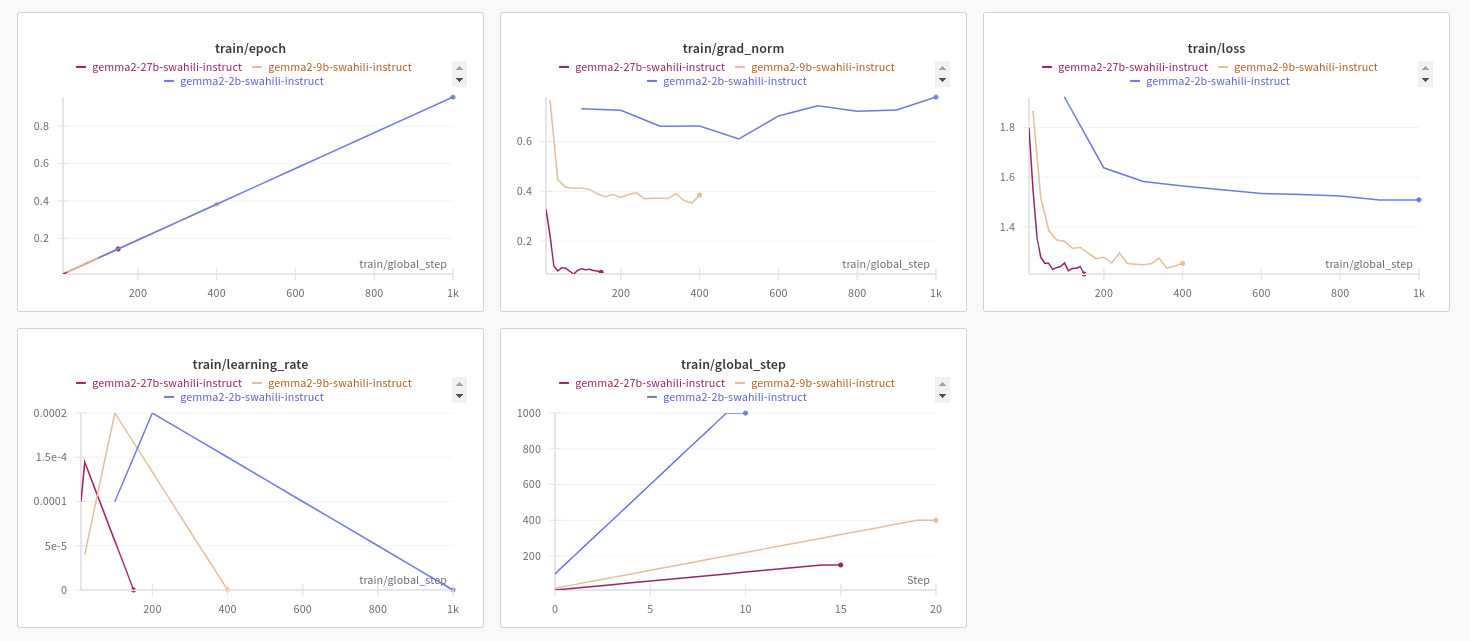





Key Observations:
1. **Gemma2-2B-IT**:
   - Initial Loss: 1.9234
   - Final Loss: 1,5085
   - Training Time: ~7.5 hours
   - Steps: 2500
   - Convergence: Steady decline with minimal fluctuation

2. **Gemma2-9B-IT**:
   - Initial Loss: 1.8663
   - Final Loss: 1.2525
   - Training Time: ~8 hours
   - Steps: 400
   - Convergence: Rapid initial improvement followed by stable optimization

3. **Gemma2-27B-IT (4-bit)**:
   - Initial Loss: 1.798
   - Final Loss: 1.2096
   - Training Time: ~9 hours
   - Steps: 150
   - Convergence: Quick adaptation despite quantization

### Preview Model Training


**Gemma2-2B-Preview training dynamics:**




![image](https://github.com/user-attachments/assets/c556349c-c99a-48a1-93c7-545c7dd90053)



Training Details:
- Initial Loss: 3.6724
- Final Loss: 3.005
- Training Time: ~8 hours
- Steps: 2500
- Notable Patterns:
  - Sharp initial loss reduction
  - Stable learning phase
  - Consistent convergence


## Resource Management

### Memory Optimization
- Gradient checkpointing enabled
- Mixed precision training (bfloat16)
- Efficient batch size selection
- Strategic gradient accumulation

### GPU Utilization
- Average VRAM Usage:
  - 2B-IT Model: ~15GB
  - 9B-IT Model: ~25GB
  - 27B-IT Model: ~35GB (with 4-bit quantization)
  - Preview Model(2B): ~15GB

### Training Stability
- Regular checkpointing
- Loss monitoring
- Gradient norm tracking
- Memory usage optimization

## Training Challenges & Solutions

### 27B Model Considerations
- Challenge: Memory constraints
- Solution: QLoRA implementation
- Impact: Successful training with minimal performance loss
- Trade-off: Slightly longer training time

### Resource Optimization
- Batch size tuning per model
- Gradient accumulation adjustment
- Checkpoint frequency optimization
- Memory-efficient forward passes

This comprehensive training analysis demonstrates the successful adaptation of Gemma 2 models across different scales while maintaining efficient resource utilization and achieving stable convergence.

# Comprehensive Benchmarking Datasets

## Introduction

Evaluating large language models (LLMs) for low-resource languages requires carefully curated benchmarks that can effectively assess both general language understanding and specific task capabilities. We present three specialized benchmarks we used for Swahili language evaluation on the based and fine-tuned models, **none of which were used during the training of our models**. We evaluated our models on unseen benchmarks to show their ability to generalize and adapt to new information and tasks.

## Benchmark Datasets

### 1. Swahili Sentiment Analysis Dataset
A specialized dataset developed by Neurotech in collaboration with Jinamizi for evaluating sentiment analysis capabilities in Swahili.

#### Dataset Characteristics:
- **Total Samples**: 3,925 text samples
- **Distribution**: 
  - Positive: 2,002 samples (51.04%)
  - Negative: 1,923 samples (48.96%)
- **Text Length Statistics**:
  - Average: 66.31 characters
  - Minimum: 3 characters
  - Maximum: 459 characters
- **Evaluation Sample**: 200 stratified samples

#### Content Coverage:
- Social media content
- News commentary
- Product reviews
- Public opinions
- Cultural discussions

### 2. Swahili MMLU (Massive Multitask Language Understanding)

A comprehensive evaluation dataset covering multiple academic and professional domains, adapted specifically for Swahili language assessment.

#### Dataset Characteristics:
- **Total Questions**: 14,042
- **Subject Areas**: 50+ distinct domains
- **Evaluation Sample**: 120 stratified samples

#### Domain Coverage:
1. Professional Fields:
   - Law
   - Medicine
   - Psychology
   - Accounting

2. Academic Disciplines:
   - Mathematics
   - Biology
   - Physics
   - Computer Science

3. Humanities:
   - Philosophy
   - World Religions
   - History

4. Social Sciences:
   - Sociology
   - Macroeconomics
   - Marketing

### 3. Wikimedia English-Swahili Translation Corpus

A carefully curated parallel corpus derived from Wikimedia content, designed to evaluate translation capabilities and cultural understanding.

#### Dataset Characteristics:
- **Source**: Wikimedia Foundation
- **Content Type**: Encyclopedic articles
- **Evaluation Sample**: 20 carefully selected translation pairs
- **Focus Areas**: 
  - Cultural context
  - Technical accuracy
  - Linguistic fluency

#### Quality Metrics:
- BLEU Score (overall)
- BLEU-1 (unigram precision)
- BLEU-2 (bigram precision)
- chrF (character n-gram F-score)

## Evaluation Strategy

### Stratified Sampling
- Carefully selected subsets for each benchmark
- Balanced representation across domains
- Statistical significance considerations

### Evaluation Metrics
1. **Quantitative Metrics**:
   - Accuracy scores
   - BLEU scores
   - F1 scores
   - Precision and recall

2. **Qualitative Assessment**:
   - Cultural relevance
   - Context understanding
   - Response coherence
   - Language naturalness

## Importance of Independent Benchmarking

The use of these **completely separate evaluation datasets** is crucial for:
1. Unbiased performance assessment
2. Real-world capability evaluation
3. Comparative analysis
4. Identification of strengths and weaknesses

These benchmarks provide a comprehensive framework for evaluating Swahili language models across diverse tasks and domains, ensuring thorough assessment of their capabilities.

In the Cells below we show you how to load these benchmarks.

### Loading Swahili Sentiment Analysis Benchmark

Dataset Overview:
--------------------------------------------------
Total number of samples: 3925

Columns:
['Unnamed: 0', 'text', 'labels']

Label Distribution:
labels
positive    2002
negative    1923
Name: count, dtype: int64

Label Percentages:
labels
positive    51.006369
negative    48.993631
Name: count, dtype: float64

Text Length Statistics:
count    3925.000000
mean       66.307771
std        47.552740
min         3.000000
25%        31.000000
50%        55.000000
75%        89.000000
max       459.000000
Name: text_length, dtype: float64


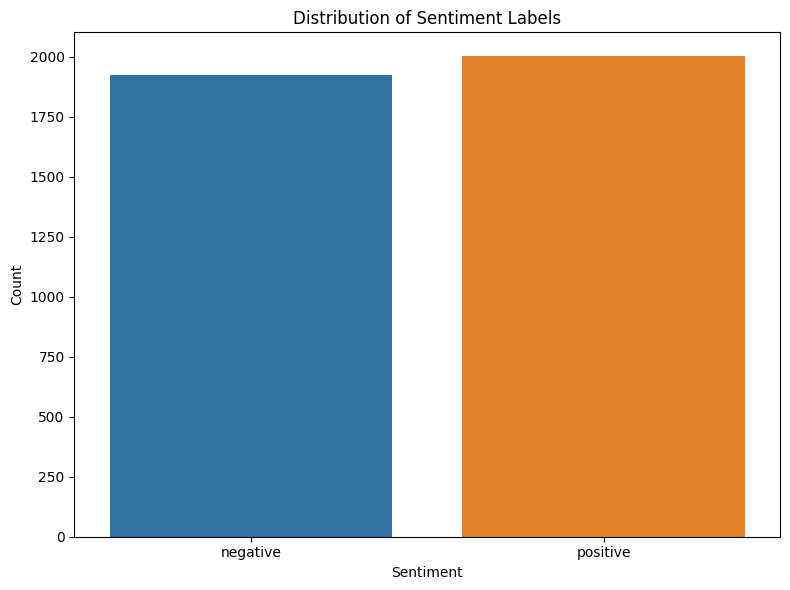

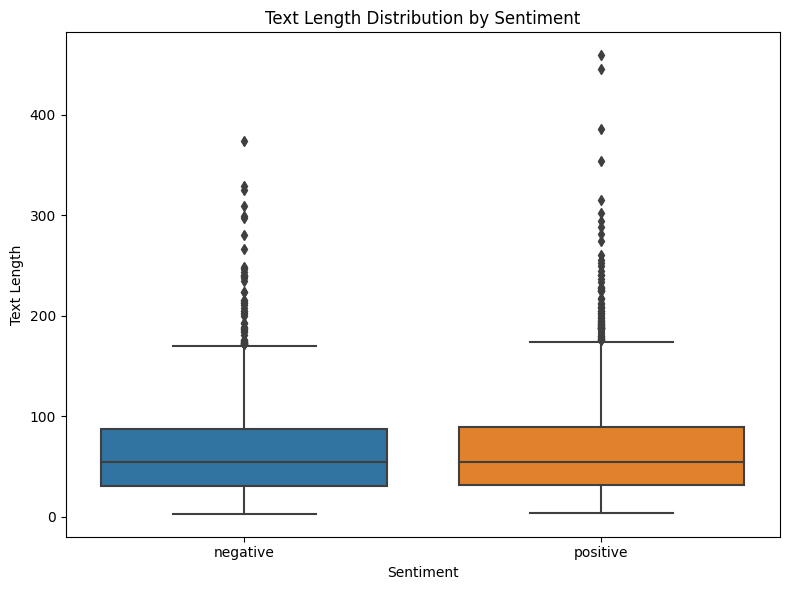


Sample Texts:
--------------------------------------------------

Sample 1:
Text: team 2019merimera alikuwa takataka
Label: negative

Sample 2:
Text: sijafurahishwa
Label: negative

Sample 3:
Text: kubuni dosari
Label: negative

Sample 4:
Text: bila kusema nilipoteza pesa zangu
Label: negative

Sample 5:
Text: sema kupoteza pesa na wakati
Label: negative


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Swahili sentiment dataset
def load_swahili_sentiment_dataset(file_path):
    """
    Load and analyze the Swahili sentiment dataset
    
    Parameters:
    - file_path: Path to the CSV file
    
    Returns:
    - Pandas DataFrame with dataset
    """
    try:
        # Read the CSV file
        df = pd.read_csv(file_path)
        
        # Basic dataset information
        print("Dataset Overview:")
        print("-" * 50)
        print(f"Total number of samples: {len(df)}")
        
        # Display column names
        print("\nColumns:")
        print(df.columns.tolist())
        
        # Label distribution
        print("\nLabel Distribution:")
        label_counts = df['labels'].value_counts()
        print(label_counts)
        print("\nLabel Percentages:")
        print(label_counts / len(df) * 100)
        
        # Text length analysis
        df['text_length'] = df['text'].str.len()
        print("\nText Length Statistics:")
        print(df['text_length'].describe())
        
        # Visualization of label distribution
        plt.figure(figsize=(8, 6))
        sns.countplot(data=df, x='labels')
        plt.title('Distribution of Sentiment Labels')
        plt.xlabel('Sentiment')
        plt.ylabel('Count')
        plt.tight_layout()
        plt.show()
        
        # Boxplot of text lengths by sentiment
        plt.figure(figsize=(8, 6))
        sns.boxplot(data=df, x='labels', y='text_length')
        plt.title('Text Length Distribution by Sentiment')
        plt.xlabel('Sentiment')
        plt.ylabel('Text Length')
        plt.tight_layout()
        plt.show()
        
        # Display a few sample texts
        print("\nSample Texts:")
        print("-" * 50)
        for i in range(min(5, len(df))):
            print(f"\nSample {i+1}:")
            print(f"Text: {df.iloc[i]['text']}")
            print(f"Label: {df.iloc[i]['labels']}")
        
        return df
    
    except FileNotFoundError:
        print(f"Error: File not found at {file_path}")
        return None
    except Exception as e:
        print(f"An error occurred: {e}")
        return None

# Path to the dataset
dataset_path = '/kaggle/input/swahili-sentiment-dataset/swahili-sentiment.csv'

# Load and analyze the dataset
sentiment_df = load_swahili_sentiment_dataset(dataset_path)

## Load Swahili MMLU benchmark to view samples

README.md:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/3.75M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14042 [00:00<?, ? examples/s]

Dataset Overview:
--------------------------------------------------
Total number of examples: 14042

Columns:
['question', 'options', 'answer', 'subject']

Subject Distribution:
subject
professional_law              1534
moral_scenarios                895
miscellaneous                  783
professional_psychology        612
high_school_psychology         545
high_school_macroeconomics     390
elementary_mathematics         378
moral_disputes                 346
prehistory                     324
philosophy                     311
Name: count, dtype: int64

Top Subject Percentages:
subject
professional_law              10.924370
moral_scenarios                6.373736
miscellaneous                  5.576129
professional_psychology        4.358354
high_school_psychology         3.881214
high_school_macroeconomics     2.777382
elementary_mathematics         2.691924
moral_disputes                 2.464036
prehistory                     2.307364
philosophy                     2.214784
Nam

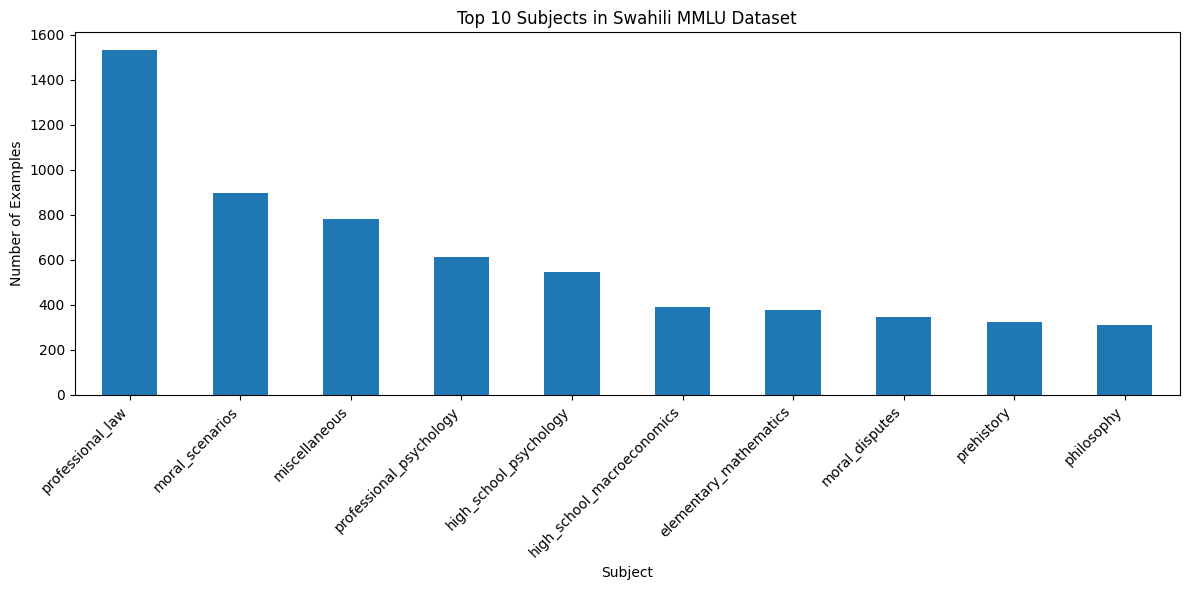


Sample Questions:
--------------------------------------------------

Sample 1:
Subject: abstract_algebra
Question: Tafuta kiwango kwa upanuzi wa sehemu uliyopewa Q(sqrt(2), sqrt(3), sqrt(18)) juu ya Q.
Options:
A: 0
B: 4
C: 2
D: 6
Correct Answer: B

Sample 2:
Subject: abstract_algebra
Question: Fanya p = (1, 2, 5, 4)(2, 3) katika S_5. Tafuta faharisi ya <p> katika S_5.
Options:
A: 8
B: 2
C: 24
D: 120
Correct Answer: C

Sample 3:
Subject: abstract_algebra
Question: Tafuta sufuri zote katika sehemu yenye kikomo iliyoashiriwa ya polinomia iliyopewa na mgawo katika sehemu hiyo. x^5 + 3x^3 + x^2 + 2x katika Z_5
Options:
A: 0
B: 1
C: 0,1
D: 0,4
Correct Answer: D

Sample 4:
Subject: abstract_algebra
Question: Kauli ya 1 | Kikundi cha sababu cha kikundi kisichokuwa cha Abeli si cha Abeli. Kauli ya 2 | Ikiwa K ni kikundi cha kawaida cha H na H ni kikundi cha kawaida cha G, basi K ni kikundi cha kawaida cha G.
Options:
A: Kweli, Kweli
B: Uongo, Uongo
C: Kweli, Uongo
D: Uongo, Kweli
Correct Ans

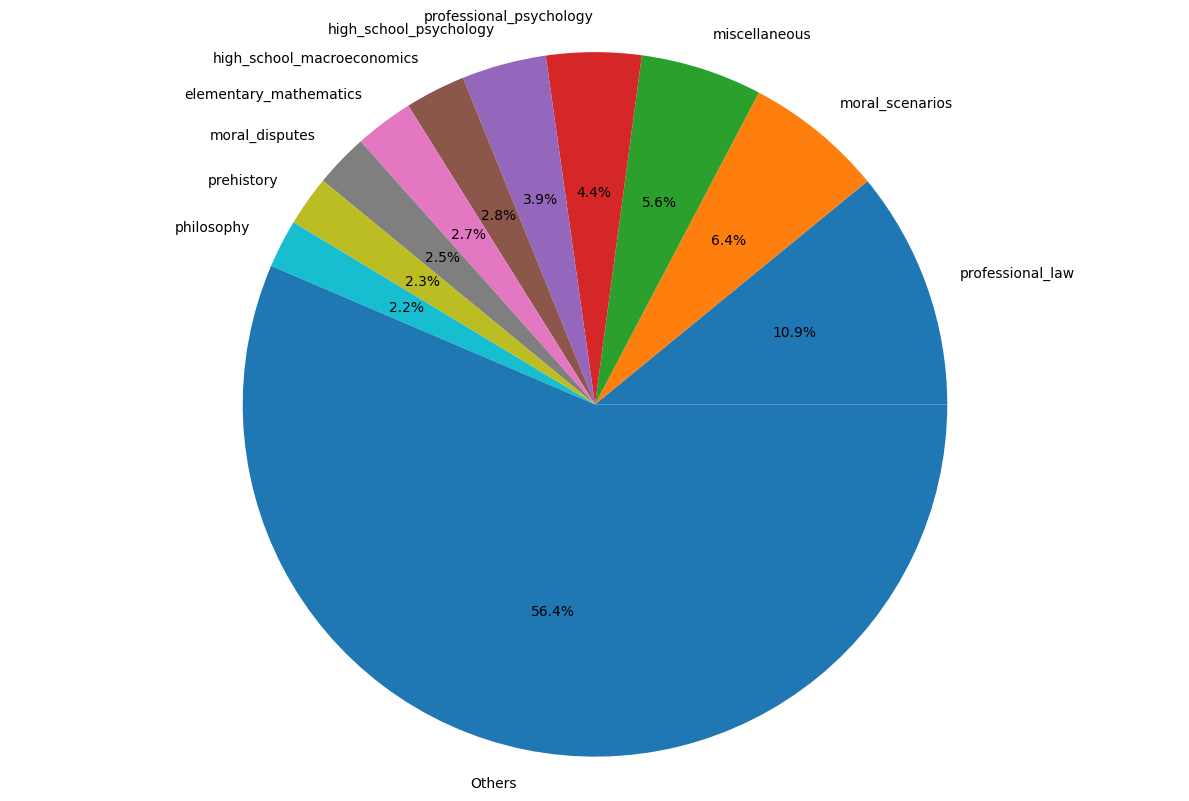

In [6]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def load_swahili_mmlu_dataset():
    """
    Load and analyze the Swahili MMLU dataset from Hugging Face
    
    Returns:
    - Loaded dataset
    """
    try:
        # Load the dataset
        sw_mmlu = load_dataset("Svngoku/swahili-mmmlu")
        
        # Convert to pandas for easier analysis
        df = sw_mmlu['train'].to_pandas()
        
        # Basic dataset information
        print("Dataset Overview:")
        print("-" * 50)
        print(f"Total number of examples: {len(df)}")
        
        # Display column names
        print("\nColumns:")
        print(df.columns.tolist())
        
        # Subject distribution
        print("\nSubject Distribution:")
        subject_counts = df['subject'].value_counts()
        print(subject_counts.head(10))  # Top 10 subjects
        
        # Percentage of top subjects
        print("\nTop Subject Percentages:")
        subject_percentages = (subject_counts / len(df) * 100).head(10)
        print(subject_percentages)
        
        # Visualize top subjects
        plt.figure(figsize=(12, 6))
        subject_counts.head(10).plot(kind='bar')
        plt.title('Top 10 Subjects in Swahili MMLU Dataset')
        plt.xlabel('Subject')
        plt.ylabel('Number of Examples')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
        
        # Display a few sample questions
        print("\nSample Questions:")
        print("-" * 50)
        for i in range(min(5, len(df))):
            print(f"\nSample {i+1}:")
            print(f"Subject: {df.iloc[i]['subject']}")
            print(f"Question: {df.iloc[i]['question']}")
            print("Options:")
            options = df.iloc[i]['options']
            for key, value in options.items():
                print(f"{key}: {value}")
            print(f"Correct Answer: {df.iloc[i]['answer']}")
        
        return sw_mmlu
    
    except Exception as e:
        print(f"An error occurred: {e}")
        return None

# Load and analyze the Swahili MMLU dataset
swahili_mmlu_dataset = load_swahili_mmlu_dataset()

# Optional: Additional analysis of subject distribution
if swahili_mmlu_dataset is not None:
    # Convert to pandas for further analysis
    df = swahili_mmlu_dataset['train'].to_pandas()
    
    # Pie chart of top 10 subjects
    plt.figure(figsize=(12, 8))
    subject_counts = df['subject'].value_counts()
    top_subjects = subject_counts.head(10)
    others = pd.Series({'Others': subject_counts[10:].sum()})
    plot_data = pd.concat([top_subjects, others])
    
    plt.pie(plot_data, labels=plot_data.index, autopct='%1.1f%%')
    plt.axis('equal')
    plt.tight_layout()
    plt.show()

### Load The Translation Benchmark

In [7]:
def load_translation_dataset(english_path, swahili_path, num_samples=5):
    """
    Load English-Swahili translation dataset from Kaggle
    
    Parameters:
    - english_path: Path to English source texts
    - swahili_path: Path to Swahili translation texts
    - num_samples: Number of samples to display
    
    Returns:
    - List of translation pairs
    """
    try:
        # Read English texts
        with open(english_path, 'r', encoding='utf-8') as f:
            english_texts = f.readlines()
        
        # Read Swahili texts
        with open(swahili_path, 'r', encoding='utf-8') as f:
            swahili_texts = f.readlines()
        
        # Validate dataset
        assert len(english_texts) == len(swahili_texts), "Mismatched number of texts"
        
        # Print dataset size
        print(f"Total number of translation pairs: {len(english_texts)}")
        
        # Display samples
        print("\nTranslation Samples:")
        print("-" * 50)
        
        for i in range(min(num_samples, len(english_texts))):
            print(f"\nSample {i+1}:")
            print("English:")
            print(english_texts[i].strip())
            print("\nSwahili:")
            print(swahili_texts[i].strip())
            print("-" * 50)
        
        # Create list of translation pairs
        translation_pairs = list(zip(
            [text.strip() for text in english_texts],
            [text.strip() for text in swahili_texts]
        ))
        
        return translation_pairs
    
    except FileNotFoundError as e:
        print(f"Error: File not found - {e}")
        return None
    except Exception as e:
        print(f"An error occurred: {e}")
        return None

# Paths to the dataset
english_path = '/kaggle/input/wikimedia-english-swahili-dataset/wikimedia.en-sw.en'
swahili_path = '/kaggle/input/wikimedia-english-swahili-dataset/wikimedia.en-sw.sw'

# Load and display translation dataset
translation_pairs = load_translation_dataset(english_path, swahili_path)

Total number of translation pairs: 16289

Translation Samples:
--------------------------------------------------

Sample 1:
English:
Arthur Cornwallis Madan (1846–1917) was a British linguist and Anglican missionary who became famous for his research in African languages and his Swahili dictionaries.

Swahili:
Arthur Cornwallis Madan (1846–1917) alikuwa mwanaisimu na mmisionari Mwanglikana anayejulikana hasa kwa utafiti wake wa lugha za Kiafrika na hasa kamusi za Kiswahili.
--------------------------------------------------

Sample 2:
English:
He was born on March 8, 1846 in the parish of Cam, Gloucestershire, England as third child of the Anglican pastor George Madan.

Swahili:
Alizaliwa 8 Machi 1846 kwenye kijiji cha Cam, Gloucestershire, Uingereza akiwa mwana wa tatu wa mchungaji Mwanglikana George Madan.
--------------------------------------------------

Sample 3:
English:
He was educated at Marlborough College and studied at Christ College of Oxford university from 1865 to 1869.

# Gemma2 Swahili Benchmarking Results ( [Full Report](https://github.com/Alfaxad/gemma2-swahili-models/blob/main/Technical-Reports/Gemma2%20Swahili%20Models%20Benchmarking%20Report.pdf) )

## Overview
Our evaluation focused on three key benchmarks using stratified sampling to ensure comprehensive assessment. Each model was tested under identical conditions, with 4-bit quantization applied to the 27B models for computational efficiency.

## 1. Sentiment Analysis Results

### Evaluation Setup
- **Sample Size**: 200 examples
- **Distribution**: Balanced positive/negative samples
- **Method**: Zero-shot classification
- **Metric**: Classification accuracy

### Performance Comparison

| Model | Base Model Accuracy | Fine-tuned Model Accuracy | Improvement |
|-------|---------------|-------------------|-------------|
| Gemma2-2B IT | 49.00% | 66.50% | +17.50%   |
| Gemma2-9B IT| 83.42% | 86.50% | +3.08%    |
| Gemma2-27B IT (4-bit) | 87.50% | 88.50%   | +1.00% |

![ada](https://github.com/user-attachments/assets/8f517c86-ba12-4697-b5c5-812dd30a7571)

### Key Observations
1. **Gemma2-2B**:
   - Most significant relative improvement (+17.50%)
   - Strong learning from fine-tuning
   - Notable jump in performance

2. **Gemma2-9B**:
   - High baseline performance
   - Consistent improvement
   - Robust sentiment understanding

3. **Gemma2-27B**:
   - Best overall performance
   - Smaller but meaningful gains
   - Strong base capabilities

## 2. Swahili MMLU Benchmark

### Evaluation Setup
- **Sample Size**: 120 questions
- **Distribution**: Stratified across 50+ subjects
- **Method**: Zero-shot multiple choice
- **Metric**: Accuracy across domains

### Performance Comparison

| Model | Base Model Accuracy | Fine-tuned Model Accuracy | Improvement |
|-------|---------------|-------------------|-------------|
| Gemma2-2B IT | 15.00% | 34.17% | +19.17%    |
| Gemma2-9B IT| 43.33% | 55.83% | +12.50%    |
| Gemma2-27B IT (4-bit) | 20.00% | 54.17%     | +34.17% |

![daa](https://github.com/user-attachments/assets/3a9eae2a-d721-4be7-a024-a392e1d6ebe2)

### Subject-Level Excellence
Models achieved 100% accuracy in:

| Subject | 2B-IT | 9B-IT | 27B-IT |
|---------|-------|-------|---------|
| Nutrition | ✓ | ✓ | ✓ |
| World Religions | ✓ | ✓ | ✓ |
| Computer Security | ✓ | ✓ | ✓ |
| International Law | ✓ | ✓ | ✓ |
| Professional Accounting | ✓ | ✓ | ✓ |
| High School Government | ✓ | ✓ | ✓ |

### Challenge Areas
Consistent challenges across models:
- High School Geography
- Microeconomics
- Virology
- Human Aging
- Sociology
- College Biology

## 3. Translation Benchmark

### Evaluation Setup
- **Sample Size**: 20 carefully selected pairs
- **Source**: Wikimedia English-Swahili corpus
- **Metrics**: BLEU, BLEU-1, BLEU-2,BLEU-3, BLEU-4 chrF
- **Focus**: Cultural and contextual accuracy

### BLEU Score Results



![bleu](https://github.com/user-attachments/assets/adc3962a-4e4c-4e9f-acaa-4ce7320e387c)


### BLEU-1 Performance



![bleu1](https://github.com/user-attachments/assets/6f99f998-926e-41d9-b6ec-058beefa51ce)


### BLEU-2 Performance


![bleu2](https://github.com/user-attachments/assets/cf48728d-9413-4338-9023-c16e519c18b4)

### BLEU-3 Performance

![download (6)](https://github.com/user-attachments/assets/b45d084e-db72-4217-b156-b264c13762a3)


### BLEU-4 Performance

![download (7)](https://github.com/user-attachments/assets/41e1f9d9-f6e7-4b96-bb89-a6b0dab6e572)


### ChRF SCORE

![download (7)](https://github.com/user-attachments/assets/41e1f9d9-f6e7-4b96-bb89-a6b0dab6e572)


## Comparative Analysis

### Model-Specific Insights

1. **Gemma2-2B-SWAHILI_IT**:
   - Strong improvement in sentiment analysis
   - Significant MMLU gains
   - Mixed translation performance
   - Best cost-benefit ratio

2. **Gemma2-9B-SWAHILI_IT**:
   - Consistent sentiment performance
   - High MMLU improvement
   - Slight translation regression
   - Balanced overall performance

3. **Gemma2-27B-SWAHILI_IT**:
   - Best sentiment analysis scores
   - Largest MMLU improvement
   - Stable translation metrics
   - Most robust performance

### Key Performance Patterns

1. **Sentiment Analysis**:
   - Consistent improvements across scales
   - Larger models show higher base performance
   - Fine-tuning benefits all models

2. **MMLU**:
   - Dramatic improvements post-fine-tuning
   - Clear scaling benefits
   - Domain-specific excellence patterns

3. **Translation**:
   - More complex performance dynamics
   - Better preservation of meaning in larger models
   - Trade-offs between different BLEU metrics



## Overall Performance Summary

This comprehensive benchmarking demonstrates:
1. Consistent improvements through fine-tuning
2. Clear scaling benefits in most tasks
3. Task-specific performance patterns
4. Strong overall adaptation to Swahili language tasks

# Gemma Swahili Models: Inference and Usage Guide



*Note: For the interest of time , we will only demonstrate how to inference Gemma2-2b-it and Gemma2-2b-swahili-it*
*please feel free to refer to our technical reports at the intro for detailed usage guidance on various tasks and models*


## Model Loading and Inference Overview

### Prerequisites
```python
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
```

## 1. 2B Model (No Quantization Required GPUs available on Kaggle)
### Loading the 2B Swahili Preview Model
```python
# Path to the model
model_path = '/kaggle/input/gemma-2-swahili/transformers/gemma2-2b-swahili-preview/1'

# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForCausalLM.from_pretrained(
    model_path,
    device_map='auto',  # Automatically distribute across available GPUs
    torch_dtype=torch.bfloat16,  # Efficient half-precision
    low_cpu_mem_usage=True
)

# Inference Function
def generate_text(prompt, max_tokens=500):
    # Prepare inputs
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    
    # Generate text
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_tokens,
        do_sample=True,
        temperature=0.7,
        top_p=0.95
    )
    
    # Decode and return generated text
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Example usage
prompt = "Eleza umuhimu wa teknolojia ya kidijitali katika maisha ya kila siku"
response = generate_text(prompt)
print(response)
```

## 2. 9B Model (Quantization Recommended for Kaggle GPUs, Can Be Loaded fully on an A100)
### Loading the 9B Swahili Instruction-Tuned Model
```python
from transformers import BitsAndBytesConfig

# Quantization configuration
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)

# Path to the model
model_path = '/kaggle/input/gemma-2-swahili/transformers/gemma2-9b-swahili-it/1'

# Load tokenizer and quantized model
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForCausalLM.from_pretrained(
    model_path,
    quantization_config=bnb_config,
    device_map='auto',
    trust_remote_code=True
)

# Inference Function (similar to 2B model)
def generate_text_9b(prompt, max_tokens=500):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_tokens,
        do_sample=True,
        temperature=0.7,
        top_p=0.95
    )
    
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Example usage
prompt = "Eleza mbinu za jadi za kuhifadhi chakula Tanzania"
response = generate_text_9b(prompt)
print(response)
```

## Best Practices and Considerations

### Model Selection
- **2B Model**: 
  - Lightweight
  - Suitable for resource-constrained environments
  - Fastest inference
  - Good for simple tasks

- **9B Model**:
  - More sophisticated
  - Requires quantization on most consumer GPUs
  - Better performance on complex tasks
  - More nuanced language understanding

### Quantization Tips
- Always use 4-bit quantization for models > 7B parameters
- Enables running large models on GPUs with limited memory
- Minimal performance degradation
- Recommended for 9B and 27B models

### Performance Optimization
- Use `torch.bfloat16` for efficient computation
- Leverage `device_map='auto'` for automatic GPU distribution
- Adjust `temperature` and `top_p` for different generation styles

### Common Inference Parameters
- `max_new_tokens`: Control response length
- `temperature`: Control randomness (0.7 is a good default)
  - Lower values (0.2-0.5): More focused, deterministic
  - Higher values (0.8-1.2): More creative, diverse
- `top_p`: Nucleus sampling threshold (0.9 is recommended)

## Troubleshooting
- Out of Memory (OOM) Error? 
  - Use quantization
  - Reduce `max_new_tokens`
  - Use smaller batch sizes
- Slow Generation?
  - Reduce `max_new_tokens`
  - Lower `temperature`

## Upcoming Features
- 27B model with QLoRA quantization
- Expanded language capabilities
- Improved domain-specific performance

## Ethical Considerations
- Verify outputs for accuracy
- Be aware of potential biases
- Use responsibly in production environments

In [12]:
def evaluate_model(prompt, model_path):
    """
    Generate Swahili text using Gemma2-2B-Swahili-IT model.
    
    Args:
        prompt (str): Input text prompt
        model_path (str): Path to model directory
    
    Returns:
        str: Generated response
    """
    try:
        # Initialize tokenizer with trust_remote_code
        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            trust_remote_code=True,
            use_fast=False  # Try using slow tokenizer
        )
        
        # Initialize model with trust_remote_code
        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            device_map="auto",
            torch_dtype=torch.bfloat16,
            low_cpu_mem_usage=True,
            trust_remote_code=True
        )
        
        # Ensure model is in evaluation mode
        model.eval()
        
        # Prepare input
        inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
        
        # Generate text
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=500,
                do_sample=True,
                temperature=0.7,
                top_p=0.95
            )
        
        # Decode response
        response = tokenizer.decode(outputs[0], skip_special_tokens=True)
        
        # Clean up
        del model, inputs, outputs
        torch.cuda.empty_cache()
        
        return response
        
    except Exception as e:
        print(f"Error type: {type(e)}")
        print(f"Error message: {str(e)}")
        raise

## Qualitative analysis: Domain Understanding

As you will notice in the cells below, fine-tuned model improves coherence, flow, and structure, providing more natural language, clearer concepts, and better content organization compared to the base model, which is repetitive and fragmented.

In [15]:
gemma2_2b_it = "/kaggle/input/gemma-2/transformers/gemma-2-2b-it/2"
print("Gemma2 2B IT response on digitial economy prompt")
prompt = "Eleza dhana ya uchumi wa kidijitali na umuhimu wake katika ulimwengu wa leo, maelezo yako yasizidi maneno 200"
# Define the concept of the digital economy and its importance in today's world. Your explanation should not exceed 200 words.
response = generate_swahili_text(prompt, gemma2_2b_it)
print(response)

Gemma2 2B IT response on digitial economy prompt


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Eleza dhana ya uchumi wa kidijitali na umuhimu wake katika ulimwengu wa leo, maelezo yako yasizidi maneno 200.

##  Dhana ya Ukulima wa Kidijitali na Ulimwengu wa Leo

Katika ulimwengu wa leo, kidijitali umekuwa miongoni mwa mambo muhimu zaidi, na uchumi wa kidijitali umekuwa na umuhimu mkubwa. Uchumi wa kidijitali ni uchumi ambapo bidhaa za kidijitali zimekuwa zilizo na uzalishaji, uundaji na utoaji wa bidhaa za kidijitali. 

Kwa mfano, uchumi wa kidijitali unaruhusu mawasiliano ya moja kwa moja, ujenzi wa biashara, na ufundi wa teknolojia.  Mbali na mawasiliano, uchumi wa kidijitali pia umekuwa na uhusiano mzuri na uchumi wa uchumi wa kijamii, na uchumi wa kijamii. 

Uchaguzi wa kidijitali umekuwa na umuhimu mkubwa katika ulimwengu wa leo.  Ikiwa tutaendelea kuendelea na teknolojia, uchumi wa kidijitali utaendelea kukua na kuunda uchumi wa kijamii.

 



In [17]:
swahili_gemma2_2b_it = "/kaggle/input/gemma-2-swahili/transformers/gemma2-2b-swahili-it/1"
print("Gemma2 2B Swahili IT response on digitial economy prompt")
prompt = "Eleza dhana ya uchumi wa kidijitali na umuhimu wake katika ulimwengu wa leo, maelezo yako yasizidi maneno 200"
# Define the concept of the digital economy and its importance in today's world. Your explanation should not exceed 200 words.
response = generate_swahili_text(prompt, swahili_gemma2_2b_it)
print(response)

Gemma2 2B Swahili IT response on digitial economy prompt


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Eleza dhana ya uchumi wa kidijitali na umuhimu wake katika ulimwengu wa leo, maelezo yako yasizidi maneno 200.

Uchumi wa kidijitali ni uchumi uliofungwa na mbinu ya teknolojia ya mtandaoni. Huonyesha mifumo ya uhamasishaji, ufuatiliaji wa biashara, na ufuatiliaji wa rasilimali. Uhamasishaji wa kidijitali ni muhimu kwa biashara, watu wanapojaribu kuingia kwenye soko la bidhaa au huduma. Ufuatiliaji wa rasilimali unafanya kazi kwa kutoa ufahamu juu ya utendaji wa biashara. Ufuatiliaji wa biashara unafanya kazi kwa kutoa ufahamu juu ya utendaji wa biashara.

Uchumi wa kidijitali ni muhimu kwa sababu inawezesha mawasiliano yenye haraka na yenye gharama nafuu, na inawezesha biashara za muda mrefu na za muda mfupi. Inasaidia watu kuingia kwenye soko la bidhaa na huduma, na inapunguza gharama za biashara kwa kuweka rasilimali za mawasiliano ya ndani.

Uchumi wa kidijitali unahusishwa na uhamasishaji wa bidhaa, ambayo ni muhimu kwa sababu inaleta faida kwa watu wanaofanya biashara. Uhamasisha

## Qualitative Analysis: Creative Writing

As you will notice below, on the task of creative writing, the base model's response shows significant limitations with a brief, illogical story about a giraffe eating hippos, lacking proper narrative development. In contrast, the fine-tuned model produces a complete, well-structured story about a giraffe facing environmental challenges and finding its place in society. The fine-tuned version demonstrates better storytelling with clear character development, conflict, and resolution, while maintaining natural Swahili language flow. For the digital economy prompt, the base model's response was fragmented and repetitive, while the fine-tuned model provided a coherent, well-organized explanation with better conceptual clarity. These comparisons clearly demonstrate how fine-tuning has improved both creative and explanatory capabilities in Swahili language generation.

In [23]:
print("Gemma2 2B IT Creative Writing")
prompt = "Tunga hadithi fupi kuhusu Twiga, isizidi maneno 200"
# Write a short story about a giraffe, under 200 words
response = generate_swahili_text(prompt, gemma2_2b_it)
print(response)

Gemma2 2B IT Creative Writing


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Tunga hadithi fupi kuhusu Twiga, isizidi maneno 200.

Twiga alikuwa mweusi na mzuri, ambaye alikuwa na shida ya kula ng'ombe za majini. Naye, alikuwa na mke mmoja, ambaye alikuwa na nguvu kubwa. 

Huko karibu na mtaa, alikuwa na mgeni mpya ambaye alikuwa na ngombe mbili za majini. Twiga alikumbana na mgeni mpya na aligundua kuwa kila mgeni alikuwa na ngombe mbili. 

Twiga alikuwa amefurahia sana. Alianza kucheza na mgeni mpya na mke wake, akiwa na ngombe mbili za majini. 



In [25]:

print("Gemma2 2B Swahili IT  Creative Writing")
prompt = "Tunga hadithi fupi kuhusu Twiga, isizidi maneno 200"
# Write a short story about a giraffe, Under 200 words
response = generate_swahili_text(prompt, swahili_gemma2_2b_it)
print(response)

Gemma2 2B Swahili IT  Creative Writing


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Tunga hadithi fupi kuhusu Twiga, isizidi maneno 200.

Twiga alikuwa mnyama mwitu wa asili ambao alikuwa na furaha ya kuishi katika jiji la bandarini. Alikuwa amefungwa kwa nyumba yake ya kawaida, lakini kwa sababu ya uchovu wake, alikuwa hana muda wa kucheza.

Hata hivyo, wakati huo huo, jiji lake lilikuwa ikipigwa na mabadiliko ya hali ya hewa. Maji yalikuwa ya kupotea, na mnamo siku moja, Twiga aliona kuwa kuna maji ya ziwa yalipotea.

Kulikuwa na hali mbaya kwa Twiga, kwani alikuwa na hofu ya kuchelewesha mabadiliko hayo na kupoteza nyumba yake ya kawaida.

Twiga alitaka kupata maji ya ziwa, lakini hakujua jinsi ya kufanya hivyo. Alitumia wakati wake kuangalia kwenye barabara, lakini hakuwa na uhakika jinsi ya kufikia ziwa.

Baada ya muda, Twiga alimwona mtu aliyeketi kwenye kiti karibu na ziwa na alimwomba msaada.

Mtu huyo alisema kuwa alikuwa na mtihani wa kufikia ziwa, na Twiga alimfuatilia. Kisha, mtihani huo ulikuwa wa kufikiria na kuwasiliana na kila kitu kilichopo karibu. Tw

# Adaptive Sentence-Boundary Completion (ASBC)

We are also introducing a novel technique for controlled text generation that combines adaptive token limits with natural sentence boundaries to produce coherent, properly terminated responses from language models. This for open-ended prompts that we noticed gemma2 original models along as our small finetuned models struggled with, this is a quick way to generate comprehensive responses, if you can not manage to rlaif/rlhf your models, it works best with clever prompt engineering

## Problem Statement
(un-rlhfed) Language models often struggle with:
- Abrupt cutoffs mid-sentence
- Inconsistent response lengths
- Unnatural text completion
- Repetitive generation

## Solution
ASBC ensures responses:
- Reach a minimum adaptive length
- End at natural sentence boundaries
- Maintain coherence
- Avoid repetition

## Mathematical Foundation

### 1. Core Components

Let $T$ be the sequence of generated tokens, where $|T|$ denotes the length of the sequence.

#### 1.1 Parameters
- $M$: Maximum allowed tokens
- $p$: Minimum proportion (typically 0.9)
- $E$: Set of end-token IDs {`.`, `!`, `?`}
- $V$: Complete vocabulary set of the model

#### 1.2 Minimum Length Function
The minimum required length is defined as:

$L_{min} = \lfloor p \cdot M \rfloor$

#### 1.3 Stopping Criterion
For a given token sequence $T$, the stopping function $S(T)$ is defined as:

$S(T) = \begin{cases}
1 & \text{if } |T| \geq L_{min} \text{ and } T_{|T|} \in E \\
0 & \text{otherwise}
\end{cases}$

### 2. Probability Space

#### 2.1 Token Generation
Let $P(t_i|T_{<i})$ be the probability of generating token $t_i$ given previous tokens $T_{<i}$.

#### 2.2 Conditional Probability
The probability of a complete sequence $T$ is:

$P(T) = \prod_{i=1}^{|T|} P(t_i|T_{<i})$

#### 2.3 Valid Sequence Probability
For a sequence to be valid under ASBC:

$P(T_{valid}) = P(T) \cdot \mathbb{1}[S(T) = 1]$

## Implementation

```python
from transformers import StoppingCriteria, StoppingCriteriaList

class SentenceAfterMinTokens(StoppingCriteria):
    """
    Stop only if:
      1) We have generated at least `min_length` tokens.
      2) The last token is one of the specified end tokens (e.g., '.', '?', '!')
    """
    def __init__(self, tokenizer, max_tokens, min_percentage=0.9, end_tokens=['.', '!', '?']):
        super().__init__()
        self.min_length = int(max_tokens * min_percentage)
        # Handle token conversion carefully
        self.end_token_ids = []
        for token in end_tokens:
            ids = tokenizer.convert_tokens_to_ids(token)
            if isinstance(ids, int) and ids != tokenizer.unk_token_id:
                self.end_token_ids.append(ids)

    def __call__(self, input_ids, scores, **kwargs):
        # Check minimum length
        if len(input_ids[0]) < self.min_length:
            return False
        
        # Check sentence ending
        return input_ids[0][-1].item() in self.end_token_ids

def generate_with_asbc(model, tokenizer, prompt, max_tokens=1024):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    
    stopping_criteria = StoppingCriteriaList([
        SentenceAfterMinTokens(tokenizer, max_tokens)
    ])
    
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_tokens,
        do_sample=True,
        temperature=0.7,
        top_p=0.95,
        stopping_criteria=stopping_criteria
    )
    
    return tokenizer.decode(outputs[0], skip_special_tokens=True)
```

## Usage Example
```python
response = generate_with_asbc(
    model,
    tokenizer,
    "Explain the benefits of renewable energy",
    max_tokens=500
)
```

## Algorithmic Properties

### Time Complexity
- Token Generation: $O(|T|)$
- Stopping Check: $O(1)$
- Total Runtime: $O(M)$ worst case

### Space Complexity
- Token Storage: $O(|T|)$
- Stopping Criteria: $O(|E|)$
- Total Space: $O(M + |E|)$

## Practical Considerations

### Hyperparameter Selection
Optimal values:
- $p \in [0.85, 0.95]$
- $M$ based on use case
- $E$ language-dependent

### Quality Metrics
Define quality function $Q(T)$:
1. Coherence: $C(T) \in [0,1]$
2. Length efficiency: $L_e(T) = \frac{|T|}{M}$
3. Natural ending: $N(T) = \mathbb{1}[T_{|T|} \in E]$

Combined quality score:
$Q(T) = \lambda_1C(T) + \lambda_2L_e(T) + \lambda_3N(T)$

where $\lambda_1 + \lambda_2 + \lambda_3 = 1$

## Key Benefits
1. Consistent Response Quality
   - Natural sentence completion
   - No mid-sentence truncation
   - Coherent text generation

2. Adaptive Length Control
   - Minimum length guarantee
   - Maximum length respect
   - Natural completion points

3. Implementation Benefits
   - Easy integration
   - Customizable parameters
   - Minimal overhead

## Limitations and Edge Cases

### Limitations
- Requires careful token ID handling
- May need tuning for different models


### Edge Cases
1. No valid ending found:
   - If $|T| = M$ and $T_{|T|} \notin E$
   - Force stop and trim to last valid end token

2. Early valid ending:
   - If $|T| < L_{min}$ and $T_{|T|} \in E$
   - Continue generation

## Extensions

### Multi-Sentence Control
Extended stopping criterion:
$S'(T) = S(T) \land (Count_{sentences}(T) \geq K)$

where $K$ is minimum sentence count.

### Context-Aware Stopping
Incorporate context vector $c$:
$S_c(T) = S(T) \land f_c(T, c) \geq \theta$

where $f_c$ measures contextual completion and $\theta$ is a threshold.

# Conclusion

## Project Overview

This research represents a groundbreaking effort to create Swahili variations of Gemma2 models, demonstrating efficient fine-tuning techniques in developing state-of-the-art models.

## Key Achievements

### Model Variations
- **Gemma-2B-Swahili-Preview**: First monolingual language modeling adaptation
- **Gemma-2B-Swahili-IT**: Instruction-tuned model for specific task understanding
- **Gemma-9B-Swahili-IT**: Enhanced multilingual capabilities
- **Gemma-27B-Swahili-IT**: State-of-the-art Swahili language model

### Technical Innovations
- Successful implementation of LoRA and QLoRA fine-tuning techniques
- Significant performance improvements across multiple benchmarks
- Efficient adaptation with minimal computational resources

## Benchmark Performance Highlights

### Sentiment Analysis
- **2B Model**: +17.50% accuracy improvement
- **9B Model**: +3.08% accuracy improvement
- **27B Model**: +1.00% accuracy improvement

### Massive Multitask Language Understanding (MMLU)
- **2B Model**: +19.17% accuracy improvement
- **9B Model**: +12.50% accuracy improvement
- **27B Model**: +34.17% accuracy improvement

## Significance and Impact

This project goes beyond mere technical achievement. It represents a crucial step towards a development of further swahili variations of leading open-source models

## Acknowledgments

### Open-Source Contributors
We extend our deepest gratitude to the incredible open-source community that made this work possible:

- **Google**: For developing the Gemma model family and making it openly available
- **Lelapa AI**: For the Inkuba-Mono dataset
- **Neurotech**: For the Swahili Sentiment Analysis dataset
- **GouRMET project**: For the english-swahili translation dataset
- **Bactrian X**: For the Swahili instructions dataset
- **Chris Ngiongolo**: For the Swahili MMLU benchmark


## Future Directions

### Research Roadmap
1. **Expanded Data Collection**
   - Gather more diverse Swahili text corpora
   - Include more domain-specific and regional variations

2. **Computational Scaling**
   - Leverage larger compute resources
   - Explore more sophisticated fine-tuning techniques
   - Investigate multi-task and continual learning approaches

3. **Domain Specific Swahili Variations**
   - Develop models for specific domains
  
